<a href="https://colab.research.google.com/github/Zaeemshahid483/DL/blob/main/Tutorial%204.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import shutil
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array, load_img
from google.colab import files

In [ ]:
uploaded = files.upload()
image_path = list(uploaded.keys())[0]
print("Uploaded image:", image_path)

Saving original.jpg to original.jpg
Uploaded image: original.jpg


In [ ]:
save_folder = "/content/Augmented_Images"
if os.path.exists(save_folder):
    shutil.rmtree(save_folder)
os.makedirs(save_folder, exist_ok=True)

In [ ]:
datagen = ImageDataGenerator(
    rotation_range=40,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=(0.5, 1.5)
)

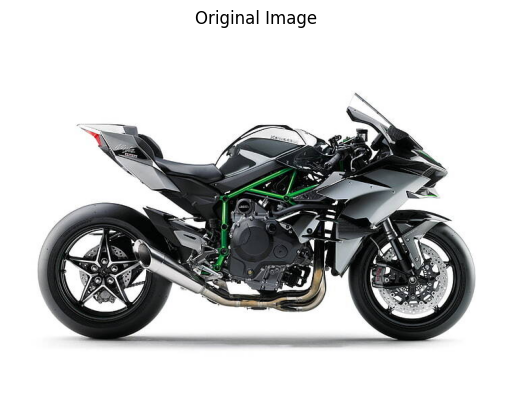

In [ ]:
img = load_img(image_path)
x = img_to_array(img)

plt.imshow(img)
plt.title("Original Image")
plt.axis('off')
plt.show()

x = x.reshape((1,) + x.shape)

In [ ]:
augmented_images = []
i = 0
for batch in datagen.flow(x, batch_size=1,
                          save_to_dir=save_folder,
                          save_prefix='image',
                          save_format='jpeg'):
    augmented_images.append(batch[0].astype('uint8'))
    i += 1
    if i >= 40:
        break

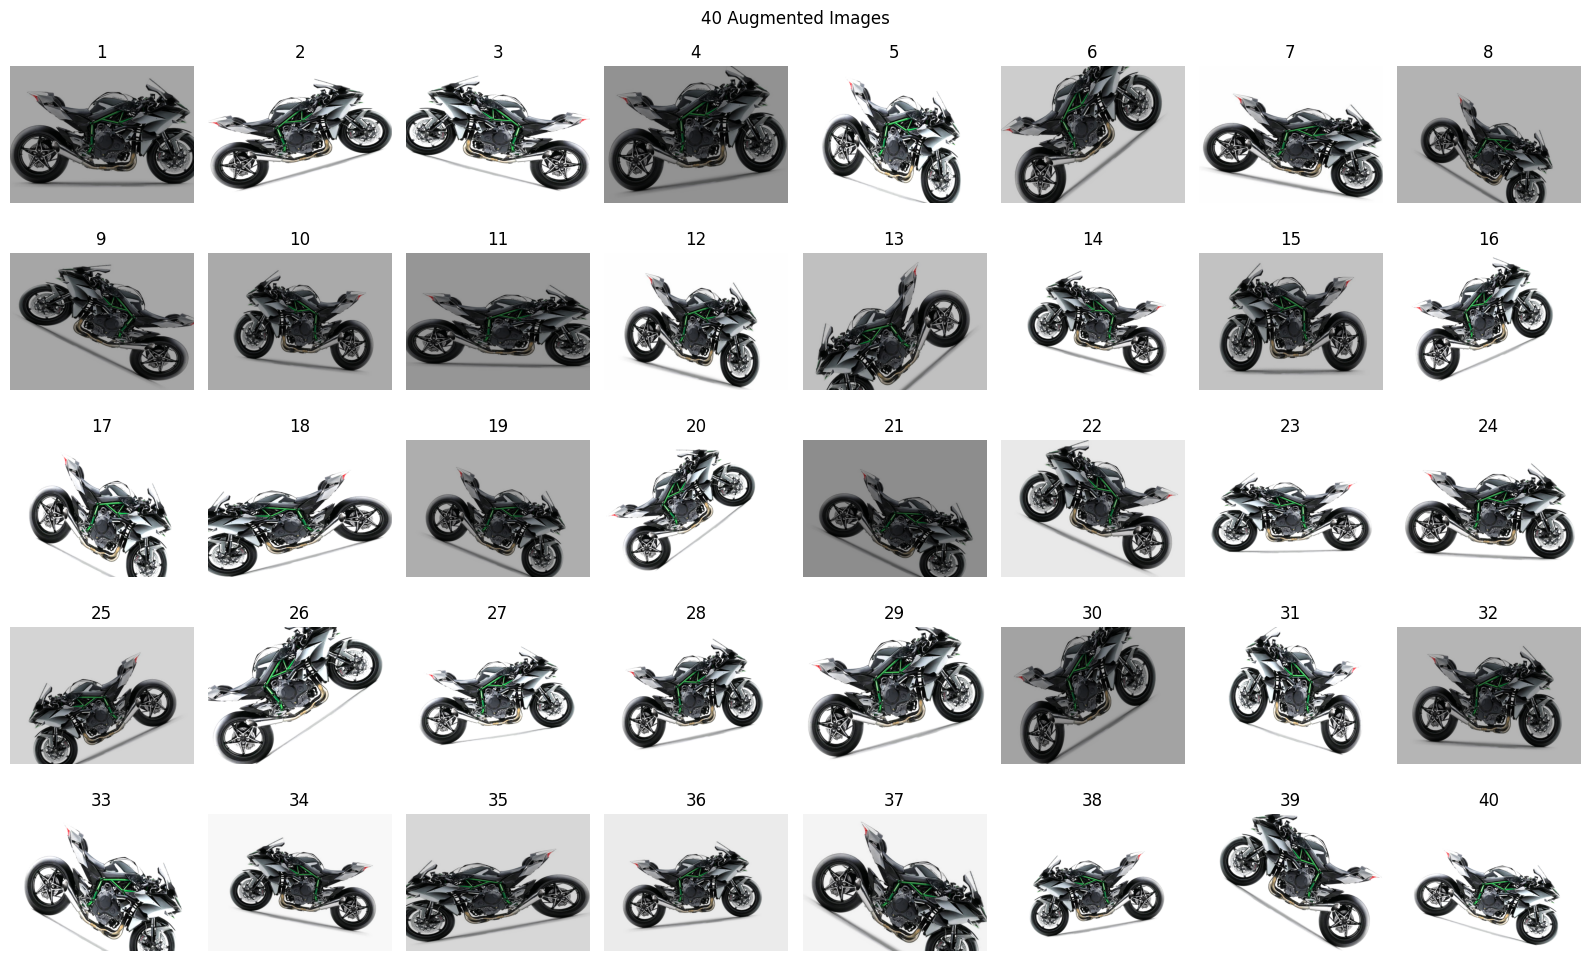

In [ ]:
plt.figure(figsize=(16, 10))
for j, image in enumerate(augmented_images):
    plt.subplot(5, 8, j + 1)
    plt.imshow(image)
    plt.title(f"{j + 1}")
    plt.axis('off')
plt.suptitle("40 Augmented Images")
plt.tight_layout()
plt.show()

In [ ]:
print(f"Augmented images are saved in the folder: {os.path.abspath(save_folder)}")
print("Number of images saved:", len(os.listdir(save_folder)))

Augmented images are saved in the folder: /content/Augmented_Images
Number of images saved: 40


In [ ]:
shutil.make_archive("/content/Augmented_Images", 'zip', save_folder)
files.download("/content/Augmented_Images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>